# Programmation Python  pour les mathématiques

**Julien Guillod**, [Sorbonne Université](http://www.sorbonne-universite.fr/),
Licence <a href="https://creativecommons.org/licenses/by-nc-nd/4.0/">CC BY-NC-ND</a>

L'entier des chapitres est disponible au format
[HTML](https://python.guillod.org/) et [PDF](https://python.guillod.org/python.pdf).
Ce notebook peut également être exécuté sur [GESIS](https://notebooks.gesis.org/binder/v2/gh/guillod/python/master?urlpath=lab/tree/chap09.ipynb).

# 9 Probabilités et statistiques

<div id="ch:proba-stats"></div>

Dans un premier temps la statistique de la proportion de nombres commençant par un certain chiffre sera étudiée. Puis dans un second des modèles probabilistes seront introduits et simulés.

**Concepts abordés:**

* statistiques et probabilités

* loi de Benford

* série harmonique aléatoire

* marche aléatoire

* histogrammes

* importation de données

* optimisation par compilation

* percolation

* transition de phase

# Exercice 9.1: Série harmonique de signe aléatoire

Le but de cet exercice est de simuler la convergence d'une série harmonique donc le signe est tiré aléatoirement. Plus précisément si $(X_i)_{i\in\mathbb{N}}$ est une suite de variables aléatoires indépendantes valant $-1$ ou $1$ avec probabilité $\frac{1}{2}$, alors on définit la somme partielle:

$$
W_0 = 0 \,, \qquad\qquad W_n = \sum_{i=1}^n \frac{X_i}{i} \,,
$$

et la question est de déterminer si la suite $(W_n)_{n\in\mathbb{N}}$ converge et si oui vers quoi.

**a)**
Écrire une fonction `sign()` qui simule la variable aléatoire $X_i$.

In [337]:
import numpy as np

def sign():
    return np.random.choice([-1, 1])

**b)**
Écrire une fonction `simulate(n)` qui retourne une liste avec une réalisation de $(W_1,W_2,\dots,W_n)$.

In [338]:
def simulate(n):
    def W(n): # Afin de calculer nos W_n
        signs = np.random.choice([-1, 1],size=n) # On génère nos n signes
        denominateurs = np.arange(1,n+1) # On génère un vecteur avec nos n dénominateurs
        x = signs/denominateurs
        return x.sum()
    
    W_v = np.vectorize(W)
    
    return W_v(np.arange(1,n+1))

# On teste notre code
simulate(10)

array([ 1.        ,  0.5       ,  0.83333333, -1.41666667, -1.61666667,
        0.88333333, -0.75952381, -0.94880952,  0.07103175,  0.38769841])

**c)**
Faire la représentation graphique de la fonction $n \mapsto W_n$ pour différentes réalisations par exemple pour $0\leq n\leq 1 000$ et émettre une conjecture quant à la convergence de la suite $(W_n)_{n\in\mathbb{N}}$.

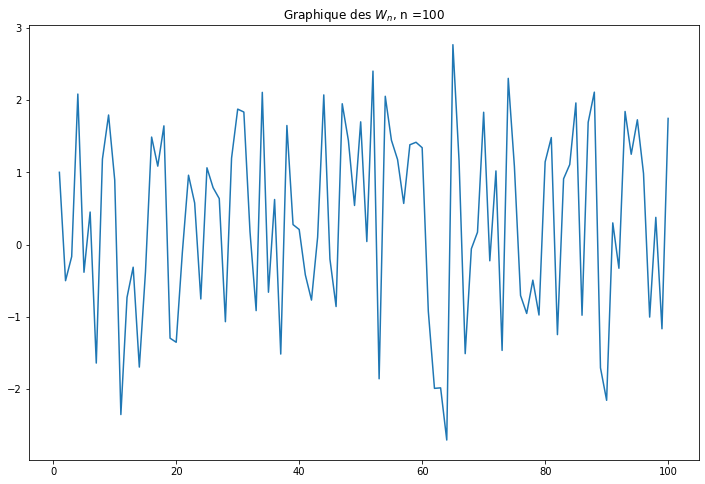

In [339]:
%matplotlib inline
import matplotlib.pyplot as plt

# Pour n = 100

n = 100
x = np.arange(1,n+1)
y = simulate(n)
plt.figure(figsize=(12,8)) # taille de la figure (en inches)
plt.plot(x,y)
plt.title(f'Graphique des $W_n$, n ={n}')
plt.show()

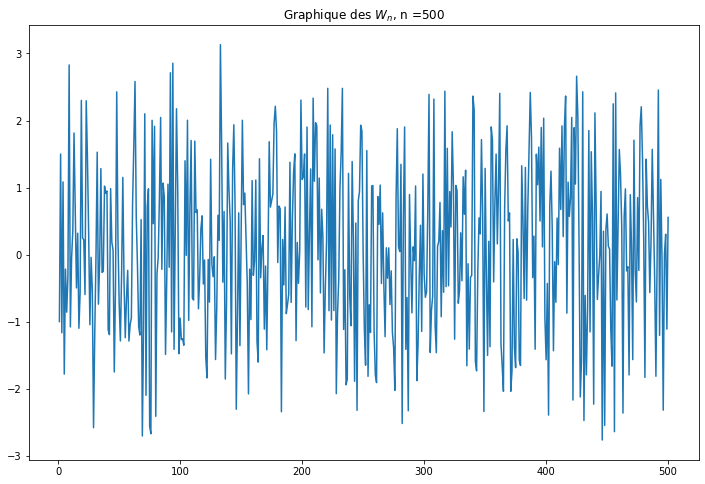

In [340]:
# Pour n = 500

n = 500
x = np.arange(1,n+1)
y = simulate(n)
plt.figure(figsize=(12,8)) # taille de la figure (en inches)
plt.plot(x,y)
plt.title(f'Graphique des $W_n$, n ={n}')
plt.show()

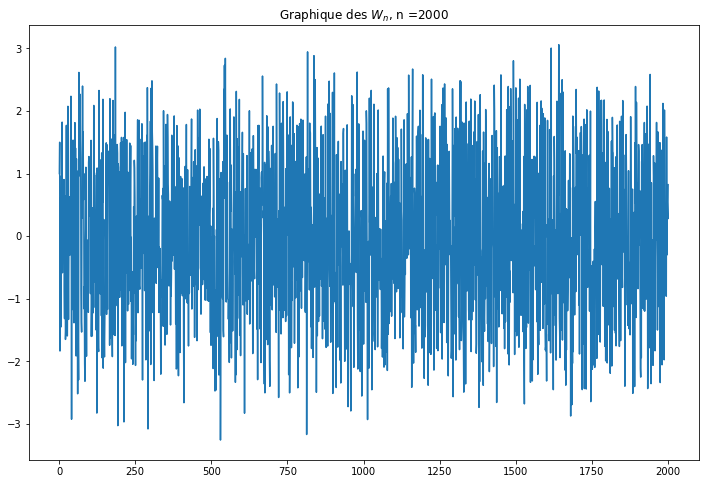

In [341]:
# Pour n = 2000

n = 2000
x = np.arange(1,n+1)
y = simulate(n)
plt.figure(figsize=(12,8)) # taille de la figure (en inches)
plt.plot(x,y)
plt.title(f'Graphique des $W_n$, n ={n}')
plt.show()


#### Il semble que les valeurs de W_n soient uniformément distribuées autour de 0. Cela suggère que que l'espérance de W_n soit nulle

**d)**
<span style="color:red">!</span>
Déterminer l'histogramme de $W_{1 000}$ pour $10^4$ ou $10^5$ réalisations pour avoir une idée de la loi de la variable aléatoire limite.

# Exercice 9.2: Loi de Benford

La loi de Benford prédit que statistiquement dans une liste de nombres donnés, la probabilité qu'un de ces nombres commence par le chiffre 1 est plus importante que celle qu'un nombre commence par le chiffre 9. Plus précisément la loi de Benford prédit que la probabilité qu'un nombre commence par le chiffre $d$ est:

$$
p_d = \log_{10}\bigg(1+\frac{1}{d}\bigg) \,,
$$

où $\log_{10}$ désigne le logarithme en base 10.
Il est possible de vérifier que la loi de Benford est la seule qui reste invariante par changement d'unités, *i.e.* en multipliant les nombres de la liste par une constante les probabilités précédentes restent inchangées.

**a)**
Écrire une fonction `firstdigit(n)` qui pour un nombre `n` donné retourne son premier chiffre et une fonction `occurrences(liste)` qui retourne le nombre d'occurrences des premiers chiffres de `liste`.

**Indication:**
Faire en sorte que la fonction `occurrences` fonctionne même si la liste contient des zéros en les ignorant.

In [342]:
def firstdigit(n):
    return int(str(n)[0])

firstdigit(2301)

2

In [343]:
def occurences(liste):
    """Retourne une liste des occurences des chiffres de 1 à 9 comme premiers chiffres des éléments de "liste"

    Args:
        liste (list):liste de nombres

    Returns:
        liste: liste des occurences de 1 à 9 comme premiers chiffres des éléments de "liste"
    """
    out = [0]*9
    for i in liste:
        out[firstdigit(i)-1]+=1 # On ajoute +1 chaque fois que l'on compte un premier élément
    return out
    

In [344]:
a= [120,22,44,195,555]

occurences(a)

[2, 1, 0, 1, 1, 0, 0, 0, 0]

**b)**
Vérifier si la loi de Benford semble satisfaite pour la suite des nombres $(2^n)_ {n\in\mathbb{N}}$ en comparant l'histogramme empirique avec la loi de Benford.

In [345]:
import numpy as np
# On définit une fonction calculant les taux d'apparitions des différents chiffres ainsi que les probabilités d'apparition de la loi de Benford

def taux_d_apparitions(l):
    """Retourne une liste des taux d'apparitions des chiffres de 1 à 9 comme premiers chiffres des éléments de "liste"
    Args:
        l (liste): liste de nombres
    Returns:
        liste: liste des taux d'apparitions de 1 à 9 comme premiers chiffres des éléments de "liste"
    """
    occ = np.array(occurences(l))
    total = occ.sum()
    return occ/total

benford = np.array([np.log10(1+1/d) for d in range(1,10)])

In [346]:
l = [2**n for n in range(200)]
taux_d_apparitions(l)

array([0.3  , 0.18 , 0.12 , 0.1  , 0.08 , 0.065, 0.055, 0.055, 0.045])

In [347]:
benford

array([0.30103   , 0.17609126, 0.12493874, 0.09691001, 0.07918125,
       0.06694679, 0.05799195, 0.05115252, 0.04575749])

#### Les résultats observés semblent cohérents avec ceux de la loi de Benford

In [348]:
# On va plus loin en calculant la distance via la norme de Chebychev entre les résultats observés et ceux de la loi de Benford
# ord=inf permet d'appliquer la norme du Max, de Chebychev

l = [2**n for n in range(200)]
p_l = taux_d_apparitions(l)

# Norme du max
np.linalg.norm(benford-p_l,ord=np.inf) 

0.004938736608299937

#### Les occurences des différents chiffres semblent décroitre avec le chiffre dans ce cas. La loi de Benford semble donc satisfaite

**c)**
Vérifier si la loi de Benford semble satisfaite pour la suite des nombres $(3n+1)_ {n\in\mathbb{N}}$.

In [349]:
l_1 = [3*n+1 for n in range(500)]
p_l_1 = taux_d_apparitions(l_1)
p_l_1

array([0.412, 0.072, 0.072, 0.078, 0.072, 0.072, 0.078, 0.072, 0.072])

#### Le résultat obtenu ne semble pas cohérent avec la distribution de Benford, puisque les valeurs ne sont pas décroissantes. Cela se vérifie aussi par un écart plus important avec les valeurs de la loi de Benford.

In [350]:
np.linalg.norm(benford-p_l_1,ord=np.inf) 

0.11097000433601878

#### L'écart observé est beaucoup plus large que dans le cas précédent, et est trop large pour que l'on puisse  considérer qu'il s'agit d'une distribution similaire à celle d'une loi de Benford

**d)**
En allant sur le site de l'INSEE à l'adresse: <https://www.insee.fr/fr/statistiques/5395878>, télécharger le fichier au format CSV contenant les données de la population par sexe et âge regroupé (POP1A). Importer ces données pour avoir la population par code postal, sexe et tranche d'âge.

**Indication:**
La documentation sur comment lire un fichier est disponible [ici](https://docs.python.org/fr/3/tutorial/inputoutput.html#reading-and-writing-files).

In [351]:
import pandas as pd
url="https://www.insee.fr/fr/statistiques/fichier/5395878/BTT_TD_POP1A_2018.zip"
df=pd.read_csv(url, sep=';')
df

/var/folders/x5/h8lrskjj57vdfkjrxk7gptdh0000gn/T/ipykernel_16354/3098586182.py:3: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv(url, sep=';')


,NIVGEO,CODGEO,LIBGEO,SEXE,AGEPYR10,NB
0,ARM,13201,Marseille 1er Arrondissement,1,0,825.531203
1,ARM,13201,Marseille 1er Arrondissement,1,3,662.466997
2,ARM,13201,Marseille 1er Arrondissement,1,6,940.259879
3,ARM,13201,Marseille 1er Arrondissement,1,11,1252.984774
4,ARM,13201,Marseille 1er Arrondissement,1,18,2256.054487
...,...,...,...,...,...,...
699855,COM,97424,Cilaos,2,25,494.194190
699856,COM,97424,Cilaos,2,40,608.508276
699857,COM,97424,Cilaos,2,55,299.685545
699858,COM,97424,Cilaos,2,65,316.034176


**e)**
Déterminer si la liste de toutes les populations par commune, sexe et âge suit la loi de Benford.

In [352]:
data = np.array(df['NB'])
taux = taux_d_apparitions(data)
print('La distribution observée est',taux)
print('\n La distribution de Benford est',benford)

La distribution observée est [0.29770097 0.17127711 0.11942246 0.09220416 0.0748021  0.06299403
 0.05364644 0.0469051  0.08104764]

 La distribution de Benford est [0.30103    0.17609126 0.12493874 0.09691001 0.07918125 0.06694679
 0.05799195 0.05115252 0.04575749]


#### Les deux distributions semblent assez similaires, on calcule la norme du max entre les de taux d'apparitions théoriques et observés

In [353]:
np.linalg.norm(benford-taux,ord=np.inf)

0.03529014753837324

**f)**
Sommer les données précédentes pour obtenir la liste des populations par commune et déterminer si elle suit la loi de Benford.

In [354]:
df2 = df.groupby('CODGEO').sum()

data_2 = np.array(df['NB'])
taux_2 = taux_d_apparitions(data_2)
print('La distribution observée est \n',taux_2)
print('\n La distribution de Benford est\n',benford)


La distribution observée est 
 [0.29770097 0.17127711 0.11942246 0.09220416 0.0748021  0.06299403
 0.05364644 0.0469051  0.08104764]

 La distribution de Benford est
 [0.30103    0.17609126 0.12493874 0.09691001 0.07918125 0.06694679
 0.05799195 0.05115252 0.04575749]


#### Les deux distributions semblent assez similaires, on calcule la norme du max entre les de taux d'apparitions théoriques et observés

In [355]:
np.linalg.norm(benford-taux_2,ord=np.inf)

0.03529014753837324

**g)**
<span style="color:red">!!</span> Lire la documentation du module Pandas disponible [ici](https://pandas.pydata.org/docs/) et l'utiliser pour refaire les deux questions précédentes mais avec le fichier de population POP1B avec les âges non regroupés.

**Indication:**
Utiliser la fonction `read_csv` de Pandas.

In [356]:
url="https://www.insee.fr/fr/statistiques/fichier/5395878/BTT_TD_POP1A_2018.zip"
df=pd.read_csv(url, sep=';')
df

/var/folders/x5/h8lrskjj57vdfkjrxk7gptdh0000gn/T/ipykernel_16354/2084658043.py:2: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv(url, sep=';')


,NIVGEO,CODGEO,LIBGEO,SEXE,AGEPYR10,NB
0,ARM,13201,Marseille 1er Arrondissement,1,0,825.531203
1,ARM,13201,Marseille 1er Arrondissement,1,3,662.466997
2,ARM,13201,Marseille 1er Arrondissement,1,6,940.259879
3,ARM,13201,Marseille 1er Arrondissement,1,11,1252.984774
4,ARM,13201,Marseille 1er Arrondissement,1,18,2256.054487
...,...,...,...,...,...,...
699855,COM,97424,Cilaos,2,25,494.194190
699856,COM,97424,Cilaos,2,40,608.508276
699857,COM,97424,Cilaos,2,55,299.685545
699858,COM,97424,Cilaos,2,65,316.034176


**h)**
<span style="color:red">!!</span> En allant sur le site de l'INSEE ou autre télécharger votre jeu de données préféré, et tester s'il suit la loi de Benford.

**Indication:**
Utiliser par exemple les comptes détaillés de l'État disponibles [ici](https://www.data.gouv.fr/fr/datasets/donnees-de-comptabilite-generale-de-letat/).

# Exercice 9.3: Ruine du joueur

Le but est de simuler l'évolution de la somme d'argent d'un joueur jouant à pile ou face. À chaque lancer le joueur gagne un euro si c'est pile et en perd un si c'est face. La probabilité d'obtenir pile est notée $p$, celle d'obtenir face $q$. En particulier $p=q=\frac{1}{2}$ si la pièce est équilibrée.

Mathématiquement, la somme $S_i$ possédée par le joueur au temps $i$ est donnée par une marche aléatoire:

$$
S_{i}=\begin{cases}
0\,, & \text{si}\:S_{i-1}=0\,,\\ 
S_{i-1}+X_{i}\,, & \text{si}\:S_{i-1}\geq1\,,
\end{cases}
$$

où les $(X_i)_ {i\geq1}$ sont des variables aléatoires indépendantes de loi $\mathbb{P}(X_i=1) = p$ et $\mathbb{P}(X_i=-1) = q$.

**a)**
Écrire une fonction `simulate(p,k,N)` qui génère une réalisation de longueur $N$ du processus à partir de $S_0=k$, c'est-à-dire qui retourne $(S_0,S_1,S_2,\dots,S_N)$. Représenter graphiquement plusieurs réalisations.

In [357]:
def simulate(p,k,n):
    
    x = np.random.choice([-1, 1],size=n,p=[1-p, p])
    def f(j):
        return x[:j].sum()
    f_v = np.vectorize(f)
    gains_n = f_v(np.arange(1,n+1)) # retourne les gains après n lancers, en supposant que le jeu se poursuit même sur des valeurs négatives
    t = n
    if -k in gains_n:
        t = np.where(gains_n == -k)[0][0] # retourne le 1er indice  où gains_n est égal à -k , donc le temps t où le joueur est ruiné
    
    basis = np.full(n,k)    
    out = basis + gains_n
    out[t:]=0
    return out

In [358]:
simulate(0.5,3,40)

array([2, 3, 2, 3, 2, 3, 4, 3, 4, 3, 2, 1, 2, 3, 2, 3, 2, 3, 4, 3, 2, 1,
       2, 1, 2, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

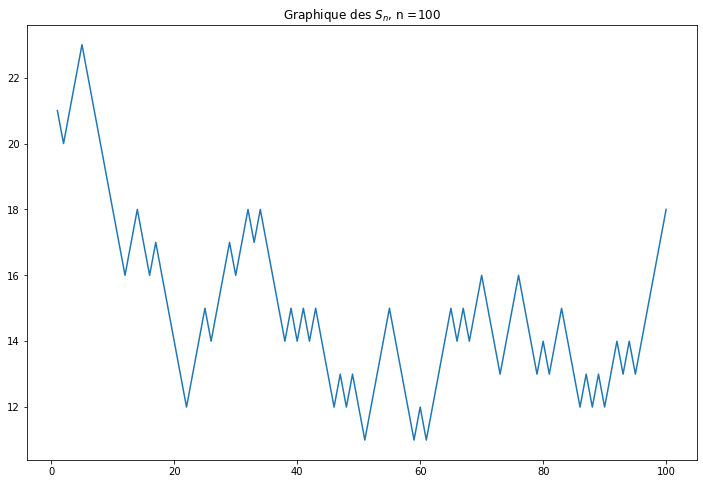

In [359]:
n = 100
x = np.arange(1,n+1)
y = simulate(0.5,20,n)
plt.figure(figsize=(12,8)) # taille de la figure (en inches)
plt.plot(x,y)
plt.title(f'Graphique des $S_n$, n ={n}')
plt.show()

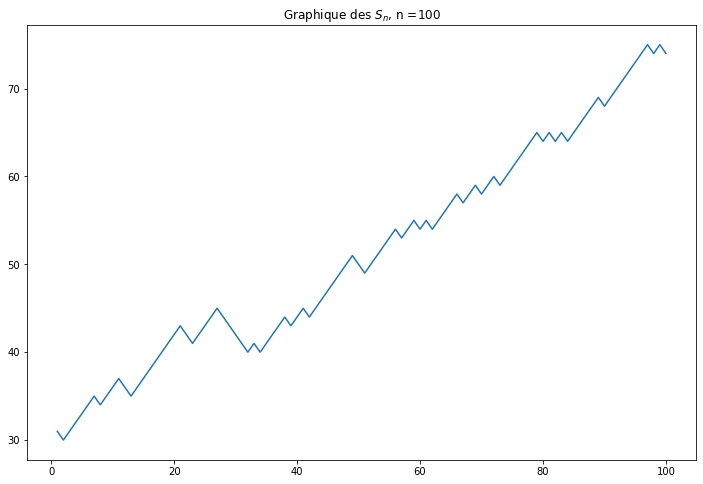

In [360]:
# Avec un p plus favorable
n = 100
x = np.arange(1,n+1)
y = simulate(0.7,30,n)
plt.figure(figsize=(12,8)) # taille de la figure (en inches)
plt.plot(x,y)
plt.title(f'Graphique des $S_n$, n ={n}')
plt.show()

**b)**
Simuler un joueur qui, commençant avec une somme $k$, joue jusqu'à tout perdre ou avoir la somme $n \geq k$.

In [375]:
def simulate_2(p,k,win):
    
    x = np.random.choice([-1, 1],size=100,p=[1-p, p])

    def f(j):
        return x[:j].sum()
    
    f_v = np.vectorize(f)
    out = f_v(np.arange(0,100)) + np.full(100,k)
    
    
    t=1
    stop_play = stop_play = (out[t] == 0) or (out[t]>=win)
    while not stop_play:
        if t == len(out):
            x = np.random.choice([-1, 1],size=100,p=[1-p, p])
            new_games = f_v(np.arange(0,100)) + np.full(100,out[t-1])
            out = np.append(out,new_games)
        stop_play = (out[t] == 0) or (out[t]>=win)
        t+=1
       
        

    return out[:t], t

In [381]:
s = simulate_2(0.5,5,10)
s

(array([5, 6, 7, 6, 7, 6, 7, 6, 7, 6, 7, 8, 9, 8, 7, 6, 7, 8, 7, 8, 9, 8,
        9, 8, 7, 8, 7, 6, 5, 4, 3, 4, 5, 4, 5, 4, 3, 2, 3, 2, 1, 0]),
 42)

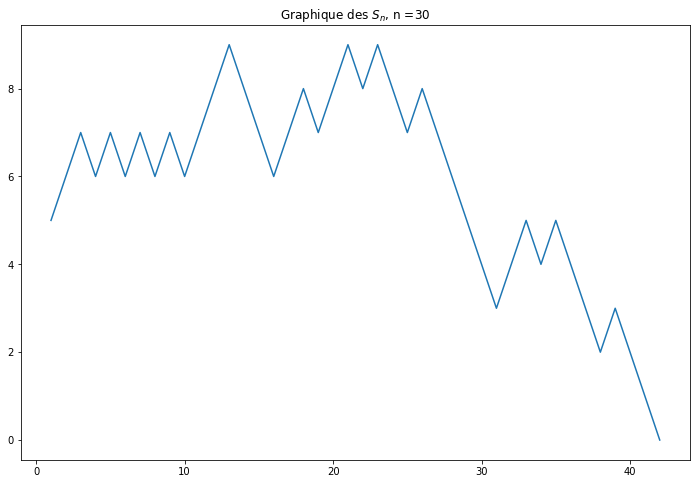

In [382]:
x = np.arange(1,s[1]+1)
y = s[0]
plt.figure(figsize=(12,8)) # taille de la figure (en inches)
plt.plot(x,y)
plt.title(f'Graphique des $S_n$, n ={30}')
plt.show()

**c)**
Si $T$ désigne le temps auquel le jeu s'arrête, *i.e.* lorsque $S_T = 0$ ou $S_T = n$, retrouver par simulation les résultats théoriques sur le temps moyen:

$$
\mathbb{E}(T)=\begin{cases}
k(n-k)\,, & \text{si}\:p=q\,,\\ 
\dfrac{n}{p-q}\dfrac{1-\rho^{k}}{1-\rho^{n}}-\dfrac{k}{p-q}\,, & \text{si}\:p\neq q\,,
\end{cases}
$$

et le lieu de sortie:

$$
\mathbb{P}(S_{T}=0)=\begin{cases}
\dfrac{n-k}{n}\,, & \text{si}\:p=q\,,\\ 
\dfrac{\rho^{k}-\rho^{n}}{1-\rho^{n}}\,, & \text{si}\:p\neq q\,,
\end{cases}
$$

où $\rho = q/p$. Pour cela on pourra faire un graphique de ces quantités en fonction de $p$ ou se contenter de considérer le cas $p=q=\frac{1}{2}$.

In [383]:
# Afin d'aller plus vite on définit f qui fixera la variable (p) dans notre simulation, afin de vectoriser le code et générer plusieurs résultats.

def moyenne_n_simuls(p,k,win,n_simuls):
    """Calcule la moyenne de n_simulations de simulate_2(p,k,win)

    Args:
        p (float): probabilité de succès à chaque tour
        k (int): somme de départ
        win (int): montant auquel le joueur se retire gagnant
        n_simuls (int): nombre de simulations
    """
    def f(k):
        return simulate_2(p,k,win)[1]

    vf = np.vectorize(f)
    simuls = vf(np.full(n_simuls,k))
    
    return simuls.sum()/n_simuls


In [388]:
p = 0.5
win = 30
n = 1000
k = 20

moyenne_n_simuls(p,k,win,n)

196.898

In [389]:
(win-k)*k

200

#### Les résultats semblent cohérents sur T, intéressons nous à la probabilité de défaite.

In [394]:
def proba_defaite_n_simuls(p,k,win,n_simuls):
    """Compte le taux de défaites sur n_simulations de simulate_2(p,k,win)

    Args:
        p (float): probabilité de succès à chaque tour
        k (int): somme de départ
        win (int): montant auquel le joueur se retire gagnant
        n_simuls (int): nombre de simulations
    """
    def f(k):
        s = simulate_2(p,k,win)
        if s[0][s[1]-1]==0:
            return 1
        return 0

    vf = np.vectorize(f)
    simuls = vf(np.full(n_simuls,k))
    
    return simuls.sum()/n_simuls


In [395]:
p = 0.5
win = 30
n = 1000
k = 20

proba_defaite_n_simuls(p,k,win,n)

0.312

In [396]:
(win-k)/win

0.3333333333333333

#### Ce qui, à nouveau, s'approche légèrement du résultat théorique

# Exercice 9.4: <span style="color:red">!!</span> Percolation

Le but est d'étudier un modèle de percolation dans un milieu poreux. Le milieu est modélisé par une matrice aléatoire de booléens qui détermine les sites qui peuvent être envahis par l'eau et ceux qui sont imperméables. Une matrice percole s'il existe un chemin d'eau allant de la ligne supérieure vers la ligne inférieure. Dans les exemples suivants, les entrées d'une matrice pouvant être envahies par l'eau sont colorées et les entrées effectivement remplies d'eau sont en bleu. La première matrice ne percole pas alors que la seconde oui:

<center><img src="https://python.guillod.org/fig/percolation-def.png" style="width:90%;max-width:800px;"></center>

**a)**
Écrire une fonction `generate(n,p)` qui génère une matrice de booléens de taille $n \times n$ telle que chaque entrée ait probabilité $p$ d'être juste et $1-p$ d'être fausse.

**Indication:**
La fonction `numpy.random.binomial` peut être utile.

**b)**
Définir une fonction `fill(isopen)` qui pour une matrice de booléens donnée renvoie une autre matrice de booléens avec les entrées envahies par l'eau.

**Indication:**
Définir une matrice de booléens `isfull` pour stocker si une entrée est remplie par l'eau ou pas, puis définir une fonction récursive `flow(isopen, isfull, i, j)` permettant d'envahir toutes les entrées possibles à partir de $(i,j)$.

**c)**
À l'aide de Matplotlib représenter le remplissage de différentes matrices générées aléatoirement.

**d)**
Définir une fonction `percolate(isopen)` permettant de déterminer si une matrice de booléens percole ou non.

**e)**
<span style="color:red">!!</span> Calculer le temps nécessaire pour déterminer si une matrice de taille $50 \times 50$ avec $p=0.9$ percole ou non. Lire la documentation du module `numba` pour réduire le temps de calcul en compilant une des fonctions: <https://numba.pydata.org/>.

**Indication:**
La fonction qui est la plus utilisée est la fonction récursive, donc c'est celle qu'il faut optimiser en la compilant.

**f)**
En faisant des statistiques, déterminer la probabilité qu'une matrice aléatoire booléenne de taille $n \times n$ avec probabilité $p$ percole. Étudier cette probabilité en fonction de $p$ et de $n$.

**Indication:**
Faire le graphique de cette probabilité de percolation en fonction de $p$ pour différentes valeurs de $n$.

**Réponse:**
Dans la limite des $n$ très grands, une matrice percole presque sûrement si $p>0.592746$ et presque jamais sinon.

**g)**
<span style="color:red">!!!</span> Les statistiques effectuées au point précédent sont un exemple typique de calculs pouvant être facilement exécutés en parallèle, car chaque cas est indépendant des autres. Paralléliser l'algorithme précédent de manière à utiliser tous les cœurs de votre processeur, par exemple à l'aide du module [`mpi4py`](https://mpi4py.readthedocs.io/).

**Indication:**
L'utilisation de Jupyter Lab pour faire du calcul parallèle est assez complexe à mettre en œuvre, il vaut mieux utiliser la ligne de commande pour exécuter un script en parallèle, par exemple pour quatre cœurs: `mpirun -n 4 script.py`. À noter que [Open MPI](https://www.open-mpi.org/) ou [MPICH](https://www.mpich.org/) doit être installé sur votre ordinateur.